# Diversificación de portafolios con Monte Carlo (versión introductoria - sin correlaciones)

Se construyen tres portafolios con los mismos cuatro activos y distintos pesos, y se simula su valor dentro de un año.

**Activos:**

| Activo | Empresa | Moneda |
|---|---|---|
| NVDA | Nvidia | USD |
| BIMBOA.MX | Grupo Bimbo | MXN |
| CEMEXCPO.MX | Cemex | MXN |
| AZN | AstraZeneca | USD |

**Portafolios:**

| Portafolio | Pesos $w$ |
|---|---|
| P1 | [1, 0, 0, 0] |
| P2 | [0.25, 0.25, 0.25, 0.25] |
| P3 | [0.1, 0.2, 0.3, 0.4] |

**Valor inicial:** $V_0 = 100{,}000$ MXN

Como dos activos cotizan en dólares, también se simula el tipo de cambio $X$ (pesos por dólar) para expresar todo en pesos.

**Procedimiento:**
1. Descargar los precios de los últimos 3 años.
2. Estimar $\mu$ y $\sigma$ con rendimientos logarítmicos.
3. Simular el precio de cada activo y el tipo de cambio a un año ($T = 1$, $M = 10{,}000$).
4. Calcular las acciones de cada activo: $N_i = \dfrac{w_i V_0}{S_{0,i}}$
5. Calcular el valor final del portafolio: $V_T = \sum_i N_i\, S_{T,i}$

En esta versión cada activo se simula de forma independiente.

### Librerías

In [2]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

## 1. Datos históricos

### Activos y tipo de cambio

In [3]:
activos = {
    "NVDA":        "USD",
    "BIMBOA.MX":   "MXN",
    "CEMEXCPO.MX": "MXN",
    "AZN":         "USD",
}

tickers = list(activos.keys())
fx      = "MXN=X"            # pesos por dólar
todos   = tickers + [fx]

### Descarga de precios de los últimos 3 años

In [4]:
data = yf.download(todos, start="2023-11-01", end="2026-11-01",
                   auto_adjust=True, progress=False)

precios = data["Close"][todos].dropna()
print(f"Observaciones: {len(precios)}")
precios.tail()

Observaciones: 727


Ticker,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN,MXN=X
Date,,,,,
2026-10-26,216.000000,63.490002,18.990000,172.059998,18.71900
2026-10-27,217.940002,64.849998,19.730000,170.080002,18.55020
2026-10-28,215.380005,61.830002,19.700001,169.509995,18.68704
2026-10-29,213.660004,63.689999,20.480000,174.399994,18.63179
2026-10-30,204.639999,66.180000,20.230000,186.649994,18.85210


## 2. Estimación de μ y σ

### Parámetros anualizados

In [5]:
log_ret = np.log(precios / precios.shift(1)).dropna()

sigma = log_ret.std() * np.sqrt(252)
mu    = log_ret.mean() * 252 + 0.5 * sigma**2
S0    = precios.iloc[-1]

pd.DataFrame({"S0": S0, "mu": mu, "sigma": sigma}).round(4)

,S0,mu,sigma
Ticker,,,
NVDA,204.6400,0.6603,0.4738
BIMBOA.MX,66.1800,0.0144,0.2995
CEMEXCPO.MX,20.2300,0.2747,0.3317
AZN,186.6500,0.1822,0.2518
MXN=X,18.8521,0.0214,0.1114


## 3. Simulación a un año

Como solo interesa el valor final, cada precio se simula directo a $T = 1$:

$$S_T = S_0 \exp\left[\left(\mu - \tfrac{\sigma^2}{2}\right)T + \sigma\sqrt{T}\,Z\right]$$

### Parámetros de simulación

In [6]:
V0 = 100_000
T  = 1
M  = 10_000

### Simulación de precios finales y tipo de cambio

In [7]:
np.random.seed(42)

ST = {}
for activo in todos:
    Z = np.random.normal(0, 1, M)
    ST[activo] = S0[activo] * np.exp((mu[activo] - 0.5*sigma[activo]**2)*T
                                     + sigma[activo]*np.sqrt(T)*Z)

ST = pd.DataFrame(ST)
ST.describe().round(2)

,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN,MXN=X
count,10000.00,10000.00,10000.00,10000.00,10000.00
mean,395.97,67.42,26.49,223.58,19.27
std,199.82,20.69,8.94,57.42,2.15
min,55.20,20.23,7.50,70.49,11.86
25%,257.40,52.65,19.98,182.15,17.77
50%,353.56,64.50,25.15,216.39,19.16
75%,486.49,79.02,31.41,257.41,20.66
max,2274.14,245.50,85.75,554.61,28.39


### Precios en pesos

Los activos en dólares se multiplican por el tipo de cambio: el de hoy para el precio inicial y el simulado de cada escenario para el precio final.

In [8]:
X0 = S0[fx]
XT = ST[fx]

S0_mxn = {}
ST_mxn = {}
for activo in tickers:
    if activos[activo] == "USD":
        S0_mxn[activo] = S0[activo] * X0
        ST_mxn[activo] = ST[activo] * XT
    else:
        S0_mxn[activo] = S0[activo]
        ST_mxn[activo] = ST[activo]

S0_mxn = pd.Series(S0_mxn)
ST_mxn = pd.DataFrame(ST_mxn)

print(f"Tipo de cambio hoy        : {X0:.4f}")
print(f"Tipo de cambio esperado   : {XT.mean():.4f}")
print()
print("Precio inicial en pesos:")
print(S0_mxn.round(2))

Tipo de cambio hoy        : 18.8521
Tipo de cambio esperado   : 19.2731

Precio inicial en pesos:
NVDA           3857.89
BIMBOA.MX        66.18
CEMEXCPO.MX      20.23
AZN            3518.74
dtype: float64


## 4. Número de acciones por activo

Solo se pueden comprar acciones enteras, así que se redondea hacia abajo:

$$N_i = \left\lfloor \frac{w_i \, V_0}{S_{0,i}} \right\rfloor$$

El dinero que no alcanza para una acción más se queda como **efectivo**:

$$\text{Efectivo} = V_0 - \sum_i N_i \, S_{0,i}$$

### Acciones entras de cada portafolio

In [9]:
portafolios = {
    "P1": np.array([1, 0, 0, 0]),
    "P2": np.array([0.25, 0.25, 0.25, 0.25]),
    "P3": np.array([0.1, 0.2, 0.3, 0.4]),
}

acciones = {}
efectivo = {}
for nombre, w in portafolios.items():
    N = np.floor(w * V0 / S0_mxn.values)
    acciones[nombre] = N
    efectivo[nombre] = V0 - np.sum(N * S0_mxn.values)

pd.DataFrame(acciones, index=tickers).T.astype(int)

,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN
P1,25,0,0,0
P2,6,377,1235,7
P3,2,302,1482,11


### Inversión real, efectivo y pesos efectivos

Al redondear, los pesos reales del portafolio ya no son exactamente los planeados.

In [10]:
filas = []
for nombre, N in acciones.items():
    invertido = N * S0_mxn.values
    fila = {"Portafolio": nombre,
            "Invertido": invertido.sum(),
            "Efectivo": efectivo[nombre]}
    for activo, monto in zip(tickers, invertido):
        fila[f"Peso real {activo} (%)"] = monto / V0 * 100
    filas.append(fila)

pd.DataFrame(filas).round(2)

,Portafolio,Invertido,Efectivo,Peso real NVDA (%),Peso real BIMBOA.MX (%),Peso real CEMEXCPO.MX (%),Peso real AZN (%)
0,P1,96447.35,3552.65,96.45,0.00,0.00,0.00
1,P2,97712.48,2287.52,23.15,24.95,24.98,24.63
2,P3,96389.20,3610.80,7.72,19.99,29.98,38.71


## 5. Valor final del portafolio

$$V_T = \sum_{i=1}^{4} N_i \, S_{T,i} + \text{Efectivo}$$

### Valor final en cada escenario

In [11]:
VT = {}
for nombre, N in acciones.items():
    VT[nombre] = (ST_mxn.values * N).sum(axis=1) + efectivo[nombre]

### Resultados

In [12]:
resumen = []
for nombre, vt in VT.items():
    rend = vt / V0 - 1
    resumen.append({
        "Portafolio": nombre,
        "Pesos": portafolios[nombre],
        "E[V_T]": vt.mean(),
        "Rend. esperado (%)": rend.mean() * 100,
        "Volatilidad (%)": rend.std(ddof=1) * 100,
        "P(pérdida) (%)": (vt < V0).mean() * 100,
    })

pd.DataFrame(resumen).round(2)

,Portafolio,Pesos,E[V_T],Rend. esperado (%),Volatilidad (%),P(pérdida) (%)
0,P1,"[1, 0, 0, 0]",194260.24,94.26,98.86,12.35
1,P2,"[0.25, 0.25, 0.25, 0.25]",136361.30,36.36,29.35,7.37
2,P3,"[0.1, 0.2, 0.3, 0.4]",125899.08,25.90,21.96,10.82


### Distribución del valor final

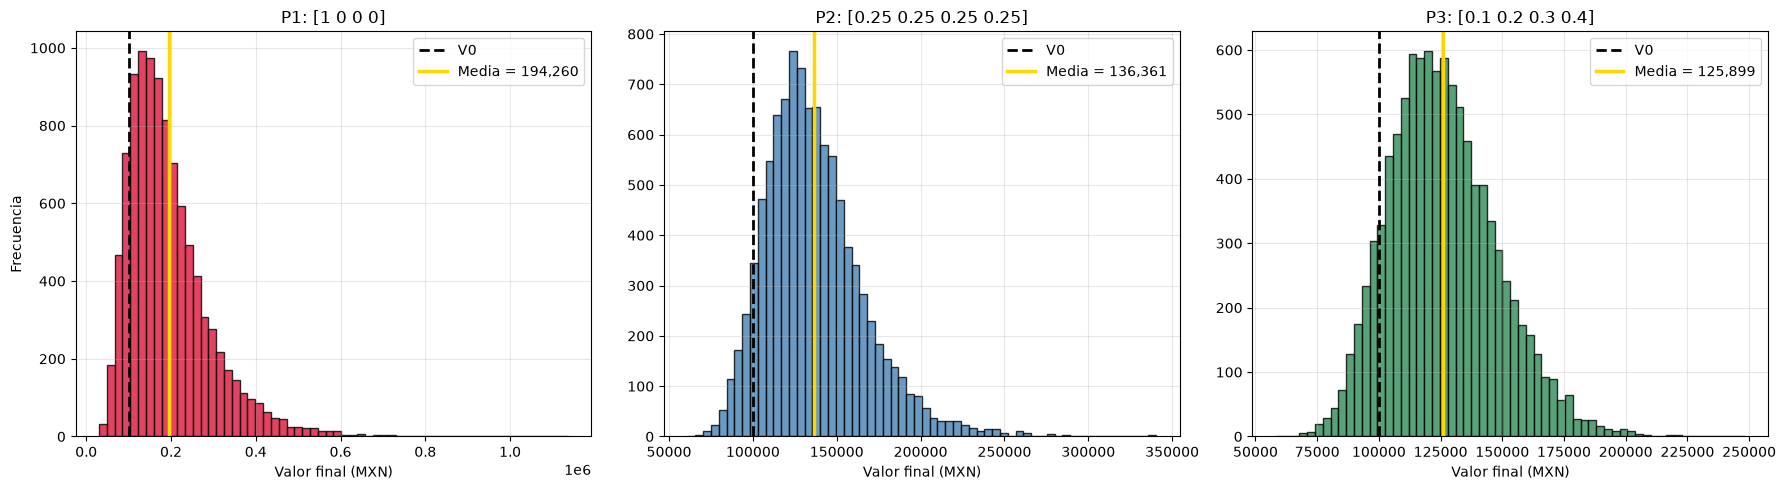

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colores = ["crimson", "steelblue", "seagreen"]

for ax, (nombre, vt), color in zip(axes, VT.items(), colores):
    ax.hist(vt, bins=60, color=color, edgecolor="black", alpha=0.8)
    ax.axvline(V0, color="black", ls="--", lw=2, label="V0")
    ax.axvline(vt.mean(), color="gold", lw=2.5, label=f"Media = {vt.mean():,.0f}")
    ax.set_title(f"{nombre}: {portafolios[nombre]}")
    ax.set_xlabel("Valor final (MXN)")
    ax.legend(); ax.grid(alpha=0.3)

axes[0].set_ylabel("Frecuencia")
plt.tight_layout()
plt.show()

---

# Conclusiones

**Diversificar reduce el riesgo de forma dramática.** P1, todo en NVDA, tiene una volatilidad cercana a 100%: el valor final puede ir de una pérdida considerable a más que triplicarse. Al repartir la inversión en cuatro activos, la volatilidad baja a 29.5% en P2 y a 21.9% en P3. El riesgo se reduce a menos de un tercio.

**El rendimiento esperado no se diversifica, se promedia.** P1 tiene el rendimiento esperado más alto (94.7%) porque NVDA tuvo un desempeño extraordinario en los últimos 3 años y su μ estimado es de 66%. P2 y P3 rinden menos porque combinan a NVDA con activos de menor rendimiento, como Bimbo, cuyo μ es casi cero. El rendimiento del portafolio es el promedio ponderado de los rendimientos individuales: diversificar no lo aumenta.

**Lo que sí mejora es el riesgo por unidad de rendimiento.** P1 rinde 94.7% con 99.6% de volatilidad: un punto de riesgo por cada punto de rendimiento. P2 rinde 36.5% con 29.5% de volatilidad, una mejor relación. Aunque gana menos en promedio, sus resultados son mucho más predecibles.

**La probabilidad de perder es menor en P2 que en P1**, 7.3% contra 12.6%, a pesar de que P1 tiene un rendimiento esperado mucho mayor. P1 depende por completo de un solo activo muy volátil, y si NVDA cae, no hay nada que compense la pérdida.

**P3 es el más conservador**, con menor rendimiento y menor volatilidad, porque reduce el peso de NVDA y le da 40% a AZN, el activo menos volátil de los cuatro. Su probabilidad de pérdida es mayor que la de P2 porque su rendimiento esperado también es menor: hay menos colchón para absorber las caídas.

**Efecto de comprar acciones enteras.** Al no poder comprar fracciones, entre 2,300 y 3,600 pesos de cada portafolio se quedan en efectivo, y los pesos reales se alejan de los planeados. En P3, NVDA queda con 7.7% en lugar de 10%. Ese efectivo no tiene riesgo, pero tampoco rendimiento, y por eso los tres portafolios rinden un poco menos que con fracciones. El efecto es mayor con activos caros como NVDA y AZN, que cuestan más de 3,500 pesos por acción.

**Una advertencia sobre los parámetros.** El μ de NVDA (66%) refleja un periodo excepcional de 3 años y no es una expectativa realista a futuro. Por eso P1 parece tan atractivo en rendimiento. Con un μ más moderado, la ventaja de diversificar sería todavía más evidente.

---

# Parte 2. Correlación entre activos

**Activos:** AAPL, MSFT y NVDA, con datos de los últimos 3 años.

La **correlación** mide qué tanto se mueven juntos los rendimientos de dos activos:

$$\rho_{ij} = \frac{\text{Cov}(r_i, r_j)}{\sigma_i \, \sigma_j}$$

| Valor | Significado |
|---|---|
| $\rho = 1$ | Se mueven exactamente igual |
| $\rho > 0$ | Tienden a subir y bajar juntos |
| $\rho \approx 0$ | No hay relación lineal |
| $\rho < 0$ | Cuando uno sube, el otro tiende a bajar |
| $\rho = -1$ | Se mueven exactamente al revés |

Es la pieza clave de la diversificación: entre más baja la correlación, más se compensan los movimientos de los activos y menor es el riesgo del portafolio. En la Parte 1 se simuló cada activo como si fuera independiente ($\rho = 0$); aquí se mide qué tan cierto es ese supuesto.

La correlación se calcula sobre los **rendimientos logarítmicos**, no sobre los precios: dos precios que suben a lo largo del tiempo aparentan una correlación alta aunque sus movimientos diarios no tengan relación entre sí.

## 1. Datos históricos

### Descarga de AAPL, MSFT y NVDA

Se descargan los tres juntos, aunque NVDA ya estaba en la Parte 1, para garantizar que usen exactamente los mismos días.

In [14]:
tickers_tec = ["AAPL", "MSFT", "NVDA"]

data_tec = yf.download(tickers_tec, start="2023-11-01", end="2026-11-01",
                       auto_adjust=True, progress=False)

precios_tec = data_tec["Close"][tickers_tec].dropna()
print(f"Observaciones: {len(precios_tec)}")
precios_tec.tail()

Observaciones: 752


Ticker,AAPL,MSFT,NVDA
Date,,,
2026-10-26,343.910004,532.599976,216.000000
2026-10-27,347.100006,531.330017,217.940002
2026-10-28,343.829987,531.010010,215.380005
2026-10-29,348.910004,530.140015,213.660004
2026-10-30,344.630005,521.909973,204.639999


### Evolución de los precios (base 100)

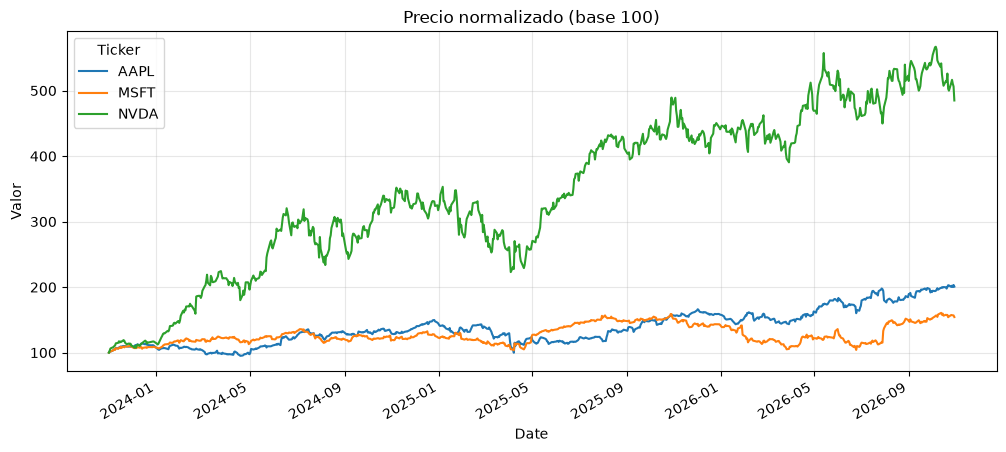

In [15]:
(precios_tec / precios_tec.iloc[0] * 100).plot(figsize=(12, 5), lw=1.5)
plt.title("Precio normalizado (base 100)")
plt.ylabel("Valor")
plt.grid(alpha=0.3)
plt.show()

### Rendimientos logarítmicos diarios

In [16]:
log_ret_tec = np.log(precios_tec / precios_tec.shift(1)).dropna()

pd.DataFrame({
    "Rend. medio anual (%)": log_ret_tec.mean() * 252 * 100,
    "Volatilidad anual (%)": log_ret_tec.std() * np.sqrt(252) * 100
}).round(2)

,Rend. medio anual (%),Volatilidad anual (%)
Ticker,,
AAPL,23.39,26.68
MSFT,14.56,25.92
NVDA,52.98,46.56


## 2. Matriz de correlaciones

### Correlación entre los rendimientos

In [17]:
correlacion = log_ret_tec.corr()
correlacion.round(4)

Ticker,AAPL,MSFT,NVDA
Ticker,,,
AAPL,1.0000,0.3343,0.2844
MSFT,0.3343,1.0000,0.4219
NVDA,0.2844,0.4219,1.0000


### Mapa de calor de la matriz de correlaciones

El color va de azul (correlación negativa) a rojo (correlación positiva). La diagonal siempre vale 1, porque cada activo está perfectamente correlacionado consigo mismo. La matriz es simétrica: la correlación de AAPL con MSFT es la misma que la de MSFT con AAPL.

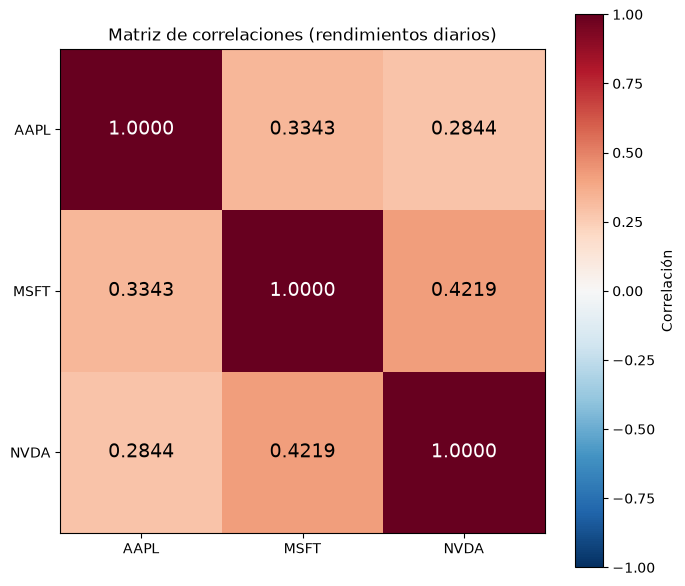

In [18]:
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(correlacion.values, cmap="RdBu_r", vmin=-1, vmax=1)

ax.set_xticks(range(len(tickers_tec)))
ax.set_xticklabels(tickers_tec)
ax.set_yticks(range(len(tickers_tec)))
ax.set_yticklabels(tickers_tec)

for i in range(len(tickers_tec)):
    for j in range(len(tickers_tec)):
        valor = correlacion.values[i, j]
        ax.text(j, i, f"{valor:.4f}", ha="center", va="center", fontsize=14,
                color="white" if abs(valor) > 0.6 else "black")

plt.colorbar(im, ax=ax, label="Correlación")
ax.set_title("Matriz de correlaciones (rendimientos diarios)")
plt.tight_layout()
plt.show()

### Dispersión de rendimientos por pares

Cada punto es un día. Si los puntos forman una nube inclinada hacia arriba, los dos activos tienden a subir y bajar juntos. Entre más angosta la nube, más alta la correlación.

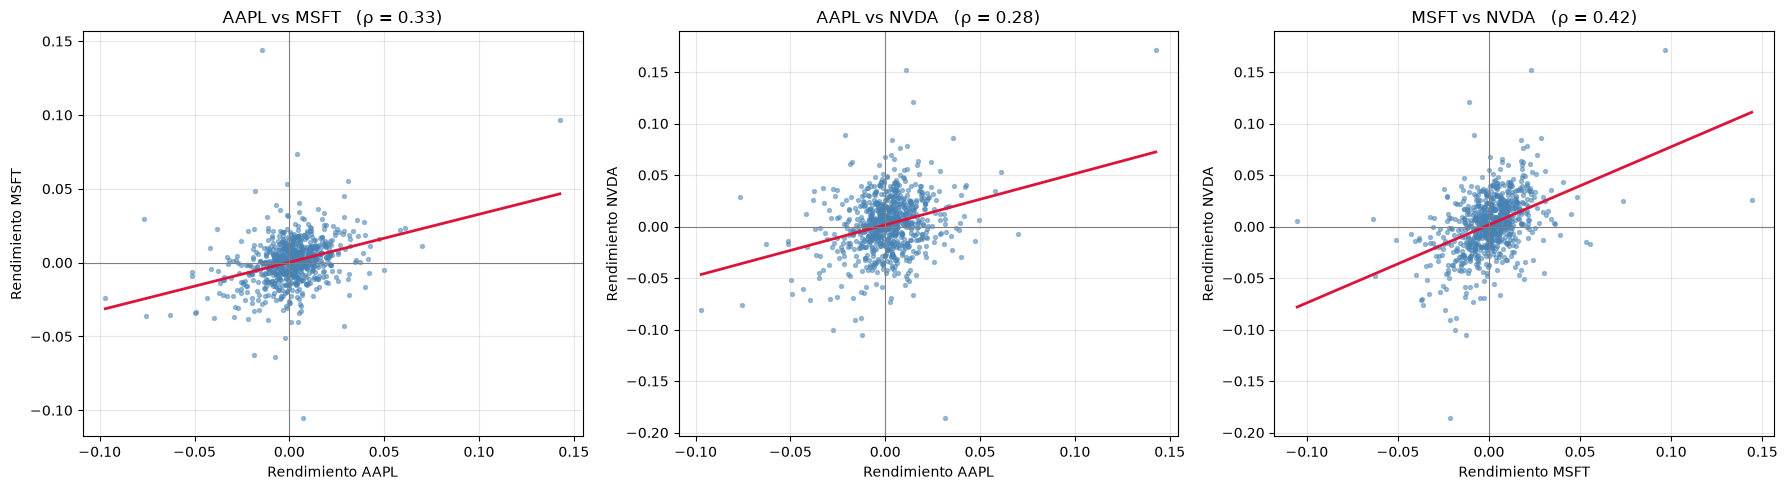

In [19]:
pares = [("AAPL", "MSFT"), ("AAPL", "NVDA"), ("MSFT", "NVDA")]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (a, b) in zip(axes, pares):
    ax.scatter(log_ret_tec[a], log_ret_tec[b], s=8, alpha=0.5, color="steelblue")

    pendiente, intercepto = np.polyfit(log_ret_tec[a], log_ret_tec[b], 1)
    x = np.linspace(log_ret_tec[a].min(), log_ret_tec[a].max(), 50)
    ax.plot(x, pendiente*x + intercepto, color="crimson", lw=2)

    ax.axhline(0, color="gray", lw=0.8)
    ax.axvline(0, color="gray", lw=0.8)
    ax.set_xlabel(f"Rendimiento {a}")
    ax.set_ylabel(f"Rendimiento {b}")
    ax.set_title(f"{a} vs {b}   (ρ = {correlacion.loc[a, b]:.2f})")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Matriz de covarianzas anualizada

La covarianza combina la correlación con la volatilidad de cada activo:

$$\text{Cov}(r_i, r_j) = \rho_{ij} \, \sigma_i \, \sigma_j$$

En la diagonal aparece la varianza de cada activo ($\sigma_i^2$). Esta matriz es la que se usa para calcular el riesgo de un portafolio y para simular activos correlacionados.

In [20]:
covarianza = log_ret_tec.cov() * 252
covarianza.round(4)

Ticker,AAPL,MSFT,NVDA
Ticker,,,
AAPL,0.0712,0.0231,0.0353
MSFT,0.0231,0.0672,0.0509
NVDA,0.0353,0.0509,0.2168


### La correlación no es constante: correlación móvil de 60 días

La matriz anterior es un promedio de los 3 años. Calculando la correlación en ventanas móviles de 60 días se ve cómo cambia con el tiempo.

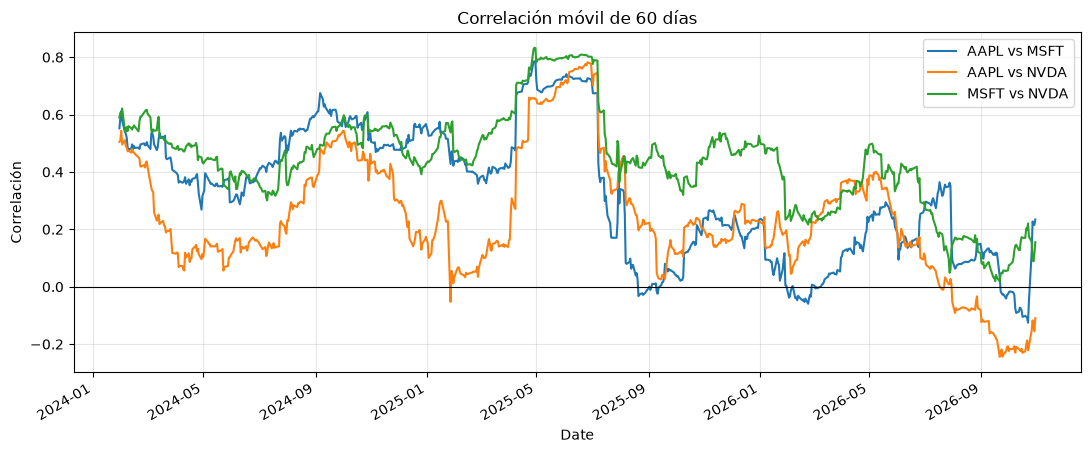

In [21]:
ventana = 60
fig, ax = plt.subplots(figsize=(13, 5))

for a, b in pares:
    log_ret_tec[a].rolling(ventana).corr(log_ret_tec[b]).plot(ax=ax, lw=1.5, label=f"{a} vs {b}")

ax.axhline(0, color="black", lw=0.8)
ax.set_title(f"Correlación móvil de {ventana} días")
ax.set_ylabel("Correlación")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

## 3. Simulación de rendimientos correlacionados con Cholesky

Para simular rendimientos que se muevan juntos como en la realidad, se genera una **normal multivariada** $Z \sim N(\mu, \Sigma)$ en cuatro pasos:

1. **Calcular** la matriz de covarianzas $\Sigma$.
2. **Descomponer** $\Sigma = L\,L^T$ con Cholesky, donde $L$ es triangular inferior.
3. **Simular** $\varepsilon \sim N(0, I)$: normales estándar independientes.
4. **Transformar** $Z = \mu + L\,\varepsilon$, que ya tiene media $\mu$ y covarianza $\Sigma$.

**Por qué funciona:**

$$\text{Cov}(\mu + L\varepsilon) = L\,\text{Cov}(\varepsilon)\,L^T = L\,I\,L^T = L\,L^T = \Sigma$$

La matriz $L$ "mezcla" los choques independientes para que tengan la correlación deseada.

### Parámetros: vector de medias y número de simulaciones

Se usan rendimientos logarítmicos anualizados, así que cada simulación representa el rendimiento de un año.

In [22]:
mu_tec = log_ret_tec.mean() * 252
M = 10_000

mu_tec.round(4)

Ticker
AAPL    0.2339
MSFT    0.1456
NVDA    0.5298
dtype: float64

### Paso 1. Matriz de covarianzas Σ

In [23]:
Sigma = covarianza.values        # anualizada, calculada en la sección anterior

pd.DataFrame(Sigma, index=tickers_tec, columns=tickers_tec).round(4)

,AAPL,MSFT,NVDA
AAPL,0.0712,0.0231,0.0353
MSFT,0.0231,0.0672,0.0509
NVDA,0.0353,0.0509,0.2168


### Paso 2. Descomposición de Cholesky: Σ = L Lᵀ

In [24]:
L = np.linalg.cholesky(Sigma)

print("Matriz L (triangular inferior):")
print(pd.DataFrame(L, index=tickers_tec, columns=tickers_tec).round(4))
print(f"\n¿L · Lᵀ reconstruye Σ?  {np.allclose(L @ L.T, Sigma)}")

Matriz L (triangular inferior):
        AAPL    MSFT    NVDA
AAPL  0.2668  0.0000  0.0000
MSFT  0.0866  0.2443  0.0000
NVDA  0.1324  0.1614  0.4162

¿L · Lᵀ reconstruye Σ?  True


### Paso 3. Muestras independientes ε ~ N(0, I)

Cada fila es una simulación y cada columna un activo. Las columnas son independientes entre sí: su matriz de covarianzas debe ser aproximadamente la identidad.

In [25]:
np.random.seed(42)
epsilon = np.random.normal(0, 1, [M, len(tickers_tec)])

print(f"Dimensión de ε: {epsilon.shape}")
print("\nCovarianza de ε (debería ser la identidad):")
print(pd.DataFrame(np.cov(epsilon.T), index=tickers_tec, columns=tickers_tec).round(3))

Dimensión de ε: (10000, 3)

Covarianza de ε (debería ser la identidad):
       AAPL   MSFT   NVDA
AAPL  1.008 -0.009 -0.019
MSFT -0.009  0.999  0.002
NVDA -0.019  0.002  0.986


### Paso 4. Transformación Z = μ + L ε

Como ε tiene una simulación por fila, el producto $L\,\varepsilon$ se escribe `epsilon @ L.T`.

In [26]:
Z_tec = mu_tec.values + epsilon @ L.T

pd.DataFrame(Z_tec, columns=tickers_tec).head()

,AAPL,MSFT,NVDA
0,0.366418,0.154888,0.842768
1,0.640253,0.220371,0.596192
2,0.655244,0.469881,0.667399
3,0.378650,0.079439,0.332988
4,0.298447,-0.300737,-0.464905


### Verificación: Z tiene la media y la covarianza históricas

In [27]:
Z_df = pd.DataFrame(Z_tec, columns=tickers_tec)

print("Medias")
print(pd.DataFrame({"Histórica": mu_tec, "Simulada": Z_df.mean()}).round(4))

print("\nCovarianzas: histórica")
print(pd.DataFrame(Sigma, index=tickers_tec, columns=tickers_tec).round(4))
print("\nCovarianzas: simulada")
print(Z_df.cov().round(4))

print("\nCorrelaciones: histórica")
print(correlacion.round(3))
print("\nCorrelaciones: simulada")
print(Z_df.corr().round(3))

Medias
      Histórica  Simulada
AAPL     0.2339    0.2324
MSFT     0.1456    0.1458
NVDA     0.5298    0.5303

Covarianzas: histórica
        AAPL    MSFT    NVDA
AAPL  0.0712  0.0231  0.0353
MSFT  0.0231  0.0672  0.0509
NVDA  0.0353  0.0509  0.2168

Covarianzas: simulada
        AAPL    MSFT    NVDA
AAPL  0.0717  0.0227  0.0331
MSFT  0.0227  0.0667  0.0501
NVDA  0.0331  0.0501  0.2123

Correlaciones: histórica
Ticker   AAPL   MSFT   NVDA
Ticker                     
AAPL    1.000  0.334  0.284
MSFT    0.334  1.000  0.422
NVDA    0.284  0.422  1.000

Correlaciones: simulada
       AAPL   MSFT   NVDA
AAPL  1.000  0.328  0.268
MSFT  0.328  1.000  0.421
NVDA  0.268  0.421  1.000


### Comparación visual: ε independientes vs Z correlacionados

A la izquierda, los choques independientes forman una nube redonda. A la derecha, después de transformarlos con $L$, la nube se inclina: los activos ya se mueven juntos.

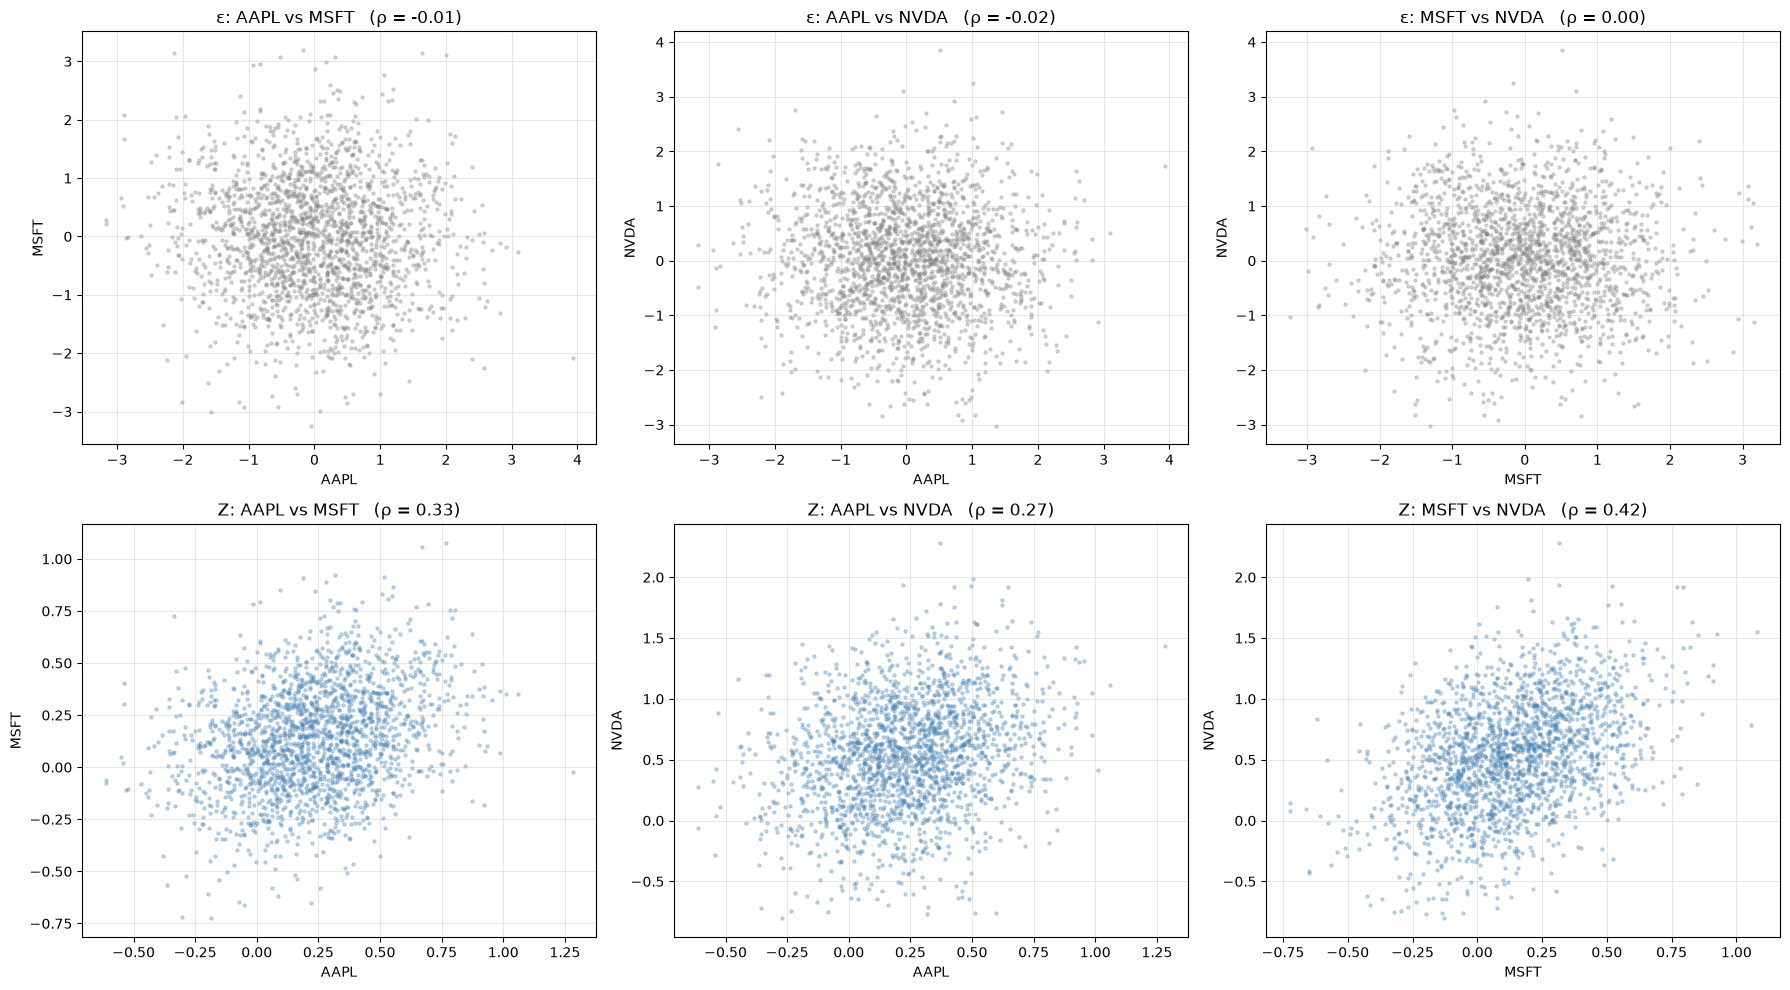

In [28]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
pares_idx = [(0, 1), (0, 2), (1, 2)]

for j, (a, b) in enumerate(pares_idx):
    axes[0, j].scatter(epsilon[:2000, a], epsilon[:2000, b], s=5, alpha=0.3, color="gray")
    axes[0, j].set_title(f"ε: {tickers_tec[a]} vs {tickers_tec[b]}   "
                         f"(ρ = {np.corrcoef(epsilon[:, a], epsilon[:, b])[0, 1]:.2f})")

    axes[1, j].scatter(Z_tec[:2000, a], Z_tec[:2000, b], s=5, alpha=0.3, color="steelblue")
    axes[1, j].set_title(f"Z: {tickers_tec[a]} vs {tickers_tec[b]}   "
                         f"(ρ = {np.corrcoef(Z_tec[:, a], Z_tec[:, b])[0, 1]:.2f})")

    for i in range(2):
        axes[i, j].set_xlabel(tickers_tec[a]); axes[i, j].set_ylabel(tickers_tec[b])
        axes[i, j].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Precios a un año

Cada fila de $Z$ es un rendimiento logarítmico a un año de los tres activos. El precio final se obtiene igual que siempre:

$$S_T = S_0 \, e^{Z}$$

La diferencia con la Parte 1 es que ahora los tres precios de cada escenario se mueven juntos, con la correlación histórica.

### Nota: por qué $Z$ ya es el movimiento browniano geométrico (GBM)

No hace falta volver a la fórmula clásica

$$S_{T,i} = S_{0,i}\,\exp\left[\left(\mu_i - \tfrac{\sigma_i^2}{2}\right)T + \sigma_i\sqrt{T}\,Z_i\right]$$

porque $Z = \mu_{log} + L\,\varepsilon$ ya contiene ese exponente completo. Hay dos razones.

**1. El promedio de los rendimientos logarítmicos ya es $\mu - \sigma^2/2$.**

En el GBM, el rendimiento logarítmico es

$$\ln\frac{S_T}{S_0} = \left(\mu - \tfrac{\sigma^2}{2}\right)T + \sigma\sqrt{T}\,Z$$

y como $Z$ tiene media cero, su promedio es $\left(\mu - \tfrac{\sigma^2}{2}\right)T$. Por lo tanto, al promediar los rendimientos logarítmicos históricos no se estima $\mu$, sino directamente $\mu - \sigma^2/2$.

En la Parte 1 se le sumaba $\sigma^2/2$ para obtener $\mu$, y luego la fórmula se lo volvía a restar: las dos operaciones se cancelan. Aquí se usa directamente el promedio logarítmico.

La diferencia de $\sigma^2/2$ entre ambos promedios es el *volatility drag*: si un activo sube 50% y luego baja 50%, el promedio aritmético es 0%, pero el capital termina en 75%. El rendimiento logarítmico capta esa pérdida por volatilidad.

**2. $L\,\varepsilon$ ya es el término aleatorio $\sigma\sqrt{T}\,Z$.**

Como $\varepsilon \sim N(0, I)$:

$$\text{Cov}(L\,\varepsilon) = L\,L^T = \Sigma$$

La diagonal de $\Sigma$ son las varianzas $\sigma_i^2$, así que cada componente $(L\,\varepsilon)_i$ es una normal con varianza $\sigma_i^2$, igual que $\sigma_i\,Z_i$. La matriz $L$ hace dos cosas a la vez: escala cada choque por su volatilidad y los mezcla para que tengan la correlación histórica.

**Juntando las dos partes:**

$$Z = \underbrace{\mu_{log}}_{\mu - \sigma^2/2} \;+\; \underbrace{L\,\varepsilon}_{\sigma\,Z \text{ correlacionada}}$$

Es exactamente el exponente del GBM con $T = 1$. La única diferencia con la Parte 1 es que los choques de los tres activos están correlacionados en lugar de ser independientes.

> Esto funciona tal cual porque $\mu$ y $\Sigma$ están anualizados y $T = 1$. Para otro horizonte se escala: $Z = \mu_{log}\,T + \sqrt{T}\,L\,\varepsilon$.

### Precio inicial de cada activo

In [29]:
S0_tec = precios_tec.iloc[-1]
S0_tec.round(2)

Ticker
AAPL    344.63
MSFT    521.91
NVDA    204.64
Name: 2026-10-30 00:00:00, dtype: float64

### Precios simulados a un año

In [30]:
ST_tec = S0_tec.values * np.exp(Z_tec)
ST_tec = pd.DataFrame(ST_tec, columns=tickers_tec)

ST_tec.describe().round(2)

,AAPL,MSFT,NVDA
count,10000.00,10000.00,10000.00
mean,450.64,624.32,386.71
std,122.81,164.05,188.27
min,155.62,238.15,52.12
25%,362.26,506.00,253.72
50%,434.82,605.53,346.65
75%,521.29,719.75,477.25
max,1438.62,1533.97,2256.97


### Verificación: precio esperado

Si $Z \sim N(\mu, \sigma^2)$, el valor esperado del precio es:

$$E[S_T] = S_0 \, e^{\mu + \sigma^2/2}$$

donde $\sigma^2$ es la varianza de cada activo, en la diagonal de $\Sigma$.

In [31]:
E_teorico = S0_tec.values * np.exp(mu_tec.values + 0.5*np.diag(Sigma))

pd.DataFrame({
    "S0": S0_tec.values,
    "E[S_T] teórico": E_teorico,
    "E[S_T] simulado": ST_tec.mean().values,
    "Rend. esperado (%)": (E_teorico / S0_tec.values - 1) * 100
}, index=tickers_tec).round(2)

,S0,E[S_T] teórico,E[S_T] simulado,Rend. esperado (%)
AAPL,344.63,451.22,450.64,30.93
MSFT,521.91,624.35,624.32,19.63
NVDA,204.64,387.39,386.71,89.30


### Distribución de los precios finales

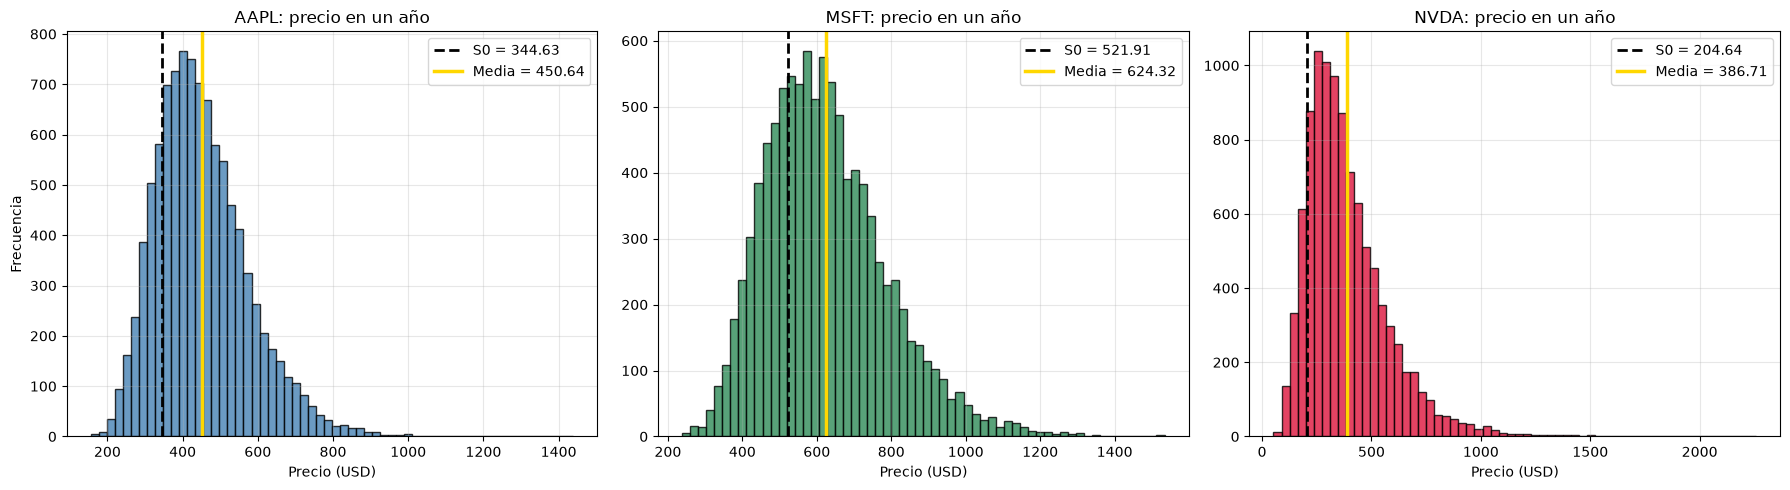

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colores = ["steelblue", "seagreen", "crimson"]

for ax, activo, color in zip(axes, tickers_tec, colores):
    ax.hist(ST_tec[activo], bins=60, color=color, edgecolor="black", alpha=0.8)
    ax.axvline(S0_tec[activo], color="black", ls="--", lw=2, label=f"S0 = {S0_tec[activo]:.2f}")
    ax.axvline(ST_tec[activo].mean(), color="gold", lw=2.5,
               label=f"Media = {ST_tec[activo].mean():.2f}")
    ax.set_title(f"{activo}: precio en un año")
    ax.set_xlabel("Precio (USD)")
    ax.legend(); ax.grid(alpha=0.3)

axes[0].set_ylabel("Frecuencia")
plt.tight_layout()
plt.show()

### Los precios simulados se mueven juntos

Cada punto es un escenario. Como la simulación respeta la correlación, los escenarios donde un activo sube mucho tienden a ser los mismos donde los otros también suben.

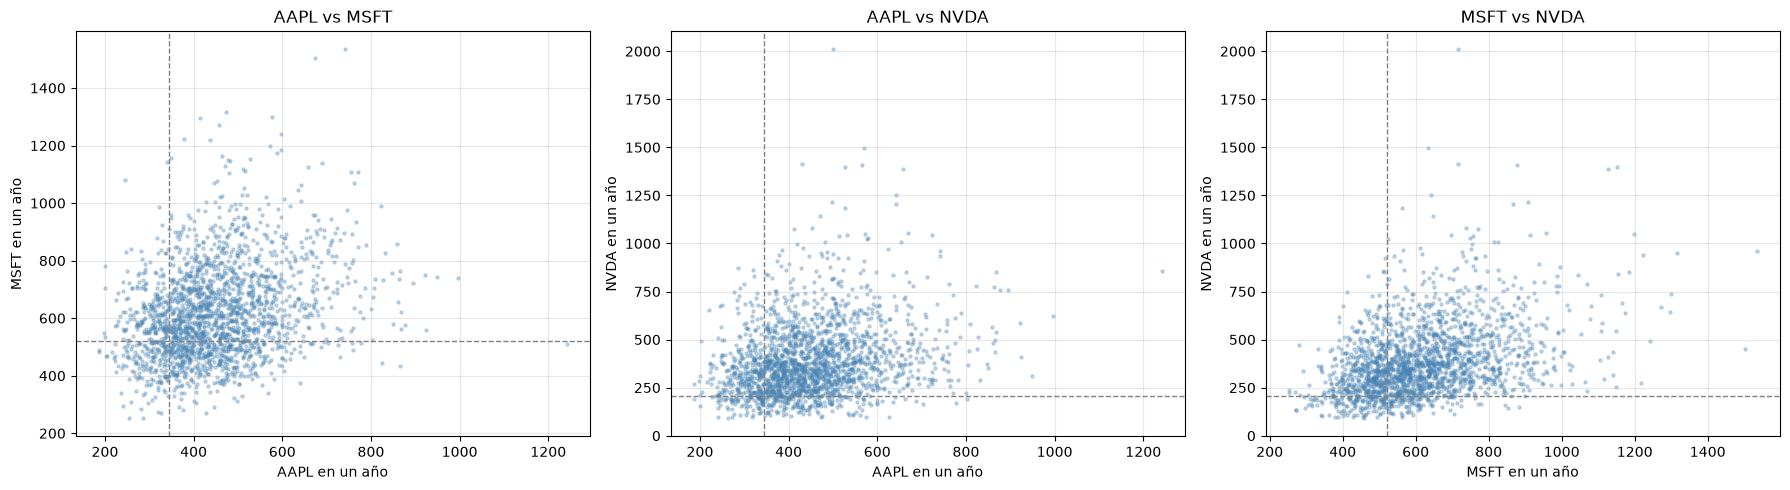

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (a, b) in zip(axes, pares):
    ax.scatter(ST_tec[a][:2000], ST_tec[b][:2000], s=5, alpha=0.3, color="steelblue")
    ax.axvline(S0_tec[a], color="gray", ls="--", lw=1)
    ax.axhline(S0_tec[b], color="gray", ls="--", lw=1)
    ax.set_xlabel(f"{a} en un año"); ax.set_ylabel(f"{b} en un año")
    ax.set_title(f"{a} vs {b}")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()